# Formula 1 | Vehicle Performance & Telemetry Intelligence
### Public timing, measured telemetry and simplified engineering models

**Analysis date: 4 November 2026 · Historical sample: 2024–2025 · Fixed seed: 42**

I investigate where lap-time differences appear, how race pace varies with tyres and conditions, and how well small predictive models perform outside their training sample. My engineering focus is the distinction between measured behaviour, derived quantities and model output.

The workflow covers environment setup, public-data acquisition, quality checks, exploratory analysis, distance alignment, time-domain physics, event-held-out lap prediction, PCA compression and a simulator surrogate. Results are interpreted alongside simple benchmarks and the limitations of the available data.

Public sampled data cannot identify a team's proprietary vehicle parameters. This is an independent project with no team affiliation.

## 1. Environment and reproducibility

I use an isolated Python environment so the analysis does not depend on packages installed elsewhere :

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install numpy==2.2.6 pandas==2.3.3 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2 seaborn==0.13.2 requests==2.34.2 ipykernel==7.4.0 jupyterlab
python -m ipykernel install --user --name f1-analysis --display-name "Python (F1 Analysis)"
jupyter lab
```

The recorded environment uses Python 3.12. Open this notebook with the F1 kernel and run cells from top to bottom. The next cell installs any missing analysis packages into the current kernel; the versions printed afterwards document the actual environment. Installation needs internet access. The analysis itself defaults to an embedded compressed snapshot of the public API responses, so the analysis can be repeated without downloading the source data again. Set `REFRESH_ONLINE = True` to retrieve the same historical sessions again. A refresh can change upstream data and results.

In [1]:
import importlib.util, subprocess, sys
requirements = {'numpy':'2.2.6','pandas':'2.3.3','scipy':'1.18.1','sklearn':'1.9.1',
                'matplotlib':'3.11.2','seaborn':'0.13.2','requests':'2.34.2'}
missing = [f"{'scikit-learn' if k=='sklearn' else k}=={v}" for k,v in requirements.items()
           if importlib.util.find_spec(k) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import os, platform, time, json, zlib, base64, hashlib, warnings
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn, requests
from scipy.optimize import least_squares
from scipy.signal import savgol_filter
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from IPython.display import display, Markdown
SEED = 42
rng = np.random.default_rng(SEED)
REFRESH_ONLINE = False
OUTPUT = Path.cwd()
sns.set_theme(style='whitegrid', palette=['#075147','#9EAD20','#31688E','#B35443'])
plt.rcParams.update({'figure.figsize':(12,5), 'axes.titleweight':'bold', 'figure.dpi':120})
pd.set_option('display.max_columns', 16)
def finish(title):
    plt.suptitle(title, fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout(); plt.show()
def scores(actual, predicted):
    error = np.asarray(predicted)-np.asarray(actual)
    return dict(mae=float(np.mean(abs(error))), rmse=float(np.sqrt(np.mean(error**2))),
                max_abs_error=float(np.max(abs(error))), n=len(error))
versions = {'Python':sys.version.split()[0], 'OS':platform.platform(), 'CPU':platform.processor(),
            'numpy':np.__version__, 'pandas':pd.__version__, 'scipy':scipy.__version__,
            'scikit-learn':sklearn.__version__, 'matplotlib':__import__('matplotlib').__version__,
            'seaborn':sns.__version__, 'requests':requests.__version__}
display(pd.Series(versions, name='Executed environment').to_frame())

,Executed environment
Python,3.12.14
OS,macOS-26.6.2-arm64-arm-64bit
CPU,arm
numpy,2.2.6
pandas,2.3.3
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2
requests,2.34.2


## 2. Public data and source manifest

I use [OpenF1](https://openf1.org/docs/) for laps, drivers, stints, weather, pit visits, race-control messages, car data and approximate locations. The API documents historical access from 2023, speed in km/h, brake as a binary 0/100 signal, and car sampling at roughly 3.7 Hz. Location coordinates have arbitrary units and are not a surveyed racing line.

The sample contains Spain, Austria and Britain races in 2024 (training), Spain 2025 (validation), Austria and Britain 2025 (test), plus Britain 2025 qualifying for telemetry. Each race weekend remains entirely within one split. This small six-event experiment supports a limited transfer test, not a general F1 forecasting claim.

The source snapshot below is JSON compressed with zlib and encoded as base64, not executable serialized objects. It preserves the responses used for this run. The online loader caches each exact request and retries rate limits and temporary failures. No credentials are required for these historical requests. Retrieval timestamps are recorded in UTC.

In [2]:
_snapshot_b64 = '...'
payload = json.loads(zlib.decompress(base64.b64decode(_snapshot_b64)))
print("Embedded historical source snapshot loaded.")

Embedded historical source snapshot loaded.


In [3]:
if REFRESH_ONLINE:
    ROOT=OUTPUT/'openf1_cache'; ROOT.mkdir(exist_ok=True); raw={}; provenance=[]
    def fetch(endpoint,**params):
     key=endpoint+'?'+requests.compat.urlencode(params)
     dest=ROOT/('api_'+__import__('hashlib').sha256(key.encode()).hexdigest()+'.json')
     if dest.exists(): result=json.loads(dest.read_text())
     else:
      for attempt in range(6):
       r=requests.get('https://api.openf1.org/v1/'+endpoint,params=params,timeout=120)
       if r.status_code in [429,500,502,503,504]:time.sleep(3*(attempt+1));continue
       r.raise_for_status();result=r.json();dest.write_text(json.dumps(result));time.sleep(.5);break
      else: raise RuntimeError(key)
     provenance.append(dict(endpoint=endpoint,url='https://api.openf1.org/v1/'+key,retrieved_utc=datetime.now(timezone.utc).isoformat(),source_rows=len(result)))
     return result
    for year,country,session,split in [(2024,'Spain','Race','train'),(2024,'Austria','Race','train'),(2024,'United Kingdom','Race','train'),(2025,'Spain','Race','validation'),(2025,'Austria','Race','test'),(2025,'United Kingdom','Race','test'),(2025,'United Kingdom','Qualifying','descriptive')]:
     s=fetch('sessions',year=year,country_name=country,session_name=session)[0];k=s['session_key'];s['split']=split;raw[str(k)]={'session':s}
     for endpoint in ['laps','drivers','stints','weather','pit','race_control']:
      print(year,country,session,endpoint,flush=True);raw[str(k)][endpoint]=fetch(endpoint,session_key=k)
     if session=='Qualifying':
      # Two quickest timed drivers; final quality filtering happens in the notebook.
      import pandas as pd
      l=pd.DataFrame(raw[str(k)]['laps']);best=l.groupby('driver_number').lap_duration.min().sort_values().index[:2]
      raw[str(k)]['car_data']=[];raw[str(k)]['location']=[]
      for driver in best:
       for endpoint in ['car_data','location']:
        print(endpoint,int(driver),flush=True);raw[str(k)][endpoint]+=fetch(endpoint,session_key=k,driver_number=int(driver))
    payload = dict(raw=raw, provenance=provenance)
    print('FINISHED',flush=True)

raw = payload["raw"]
provenance = pd.DataFrame(payload["provenance"])
display(provenance[["endpoint","source_rows","retrieved_utc"]].groupby("endpoint").agg({"source_rows":"sum","retrieved_utc":"min"}))

,source_rows,retrieved_utc
endpoint,,
car_data,38188,2026-11-04T15:10:29.572172+00:00
drivers,139,2026-11-04T15:09:10.591591+00:00
laps,7129,2026-11-04T15:09:09.959309+00:00
location,39402,2026-11-04T15:10:31.473205+00:00
pit,346,2026-11-04T15:09:12.609991+00:00
race_control,779,2026-11-04T15:09:13.255411+00:00
sessions,7,2026-11-04T15:09:09.010452+00:00
stints,465,2026-11-04T15:09:11.237489+00:00
weather,1002,2026-11-04T15:09:11.884866+00:00


The following preparation preserves all source lap rows. I create flags instead of deleting slow laps indiscriminately. A lap is *analysis eligible* when its timing and sectors reconcile within 0.15 s, it is not a pit/out lap or a deleted lap, and it does not overlap a flagged interruption. OpenF1 does not supply FastF1's `IsAccurate` field: eligibility is my documented approximation, not an official accuracy certification.

I conservatively treat each yellow/red/double-yellow message as a 90-second caution interval, extend safety-car/VSC deployment until ending or a green flag, and flag overlapping laps for every driver. This can exclude unaffected drivers and can miss unreported/local incidents. Those limitations are preferable to silently describing all laps as clean. A 107% pace screen is used only for qualifying comparisons, never for race-target selection.

Weather is matched **backwards** to lap start with a 120-second tolerance within each session. Tyre age at lap start is stint starting age plus completed laps in that stint. These are operational pre-lap features; pit/out laps are excluded from prediction, and the target population is completed, eligible laps rather than every attempted lap.

In [4]:
def utc(values):
    return pd.to_datetime(values, utc=True, format='mixed')
frames, manifests = [], []
for sid, data in raw.items():
    session = data['session']
    d = pd.DataFrame(data['laps']).rename(columns={
        'lap_duration':'lap_s','duration_sector_1':'sector1_s','duration_sector_2':'sector2_s',
        'duration_sector_3':'sector3_s','st_speed':'speed_trap_kmh'})
    d['lap_start_utc'] = utc(d.date_start)
    d['lap_end_utc'] = d.lap_start_utc + pd.to_timedelta(d.lap_s, unit='s')
    drivers = pd.DataFrame(data['drivers']).drop_duplicates('driver_number')
    d = d.merge(drivers[['driver_number','name_acronym','team_name']].rename(
        columns={'name_acronym':'driver','team_name':'team'}), on='driver_number', validate='many_to_one')
    d['session_id'] = str(sid); d['year'] = session['year']
    d['event'] = session['circuit_short_name']; d['session'] = session['session_name']
    d['split'] = session['split']
    d['lap_key'] = d.session_id+'_'+d.driver_number.astype(str)+'_'+d.lap_number.astype(str)
    d['stint'] = np.nan; d['compound'] = pd.Series(None,index=d.index,dtype='object')
    d['tyre_age_start_laps'] = np.nan
    for st in data['stints']:
        mask = d.driver_number.eq(st['driver_number']) & d.lap_number.between(st['lap_start'],st['lap_end'])
        d.loc[mask,'stint'] = st['stint_number']; d.loc[mask,'compound'] = st['compound']
        age = st.get('tyre_age_at_start')
        if age is not None:
            d.loc[mask,'tyre_age_start_laps'] = age+d.loc[mask,'lap_number']-st['lap_start']
    pits = {(p['driver_number'],p['lap_number']) for p in data['pit']}
    d['pit_lap'] = [(n,l) in pits for n,l in zip(d.driver_number,d.lap_number)]
    d['pit_out_lap'] = d.is_pit_out_lap.fillna(True).astype(bool)
    d['deleted_lap'] = False; d['interruption_flag'] = False
    rc = sorted(data['race_control'], key=lambda r:r['date'])
    intervals = []; sc_start = None
    for message in rc:
        t = utc(message['date']); text = message.get('message','').upper(); flag = message.get('flag')
        if flag in ['YELLOW','DOUBLE YELLOW','RED']:
            intervals.append((t,t+pd.Timedelta(seconds=90)))
        if 'DEPLOYED' in text and ('SAFETY CAR' in text or 'VSC' in text):
            if sc_start is None: sc_start=t
        if sc_start is not None and (flag=='GREEN' or 'ENDING' in text or 'IN THIS LAP' in text):
            intervals.append((sc_start,t+pd.Timedelta(seconds=120))); sc_start=None
        if 'DELETED' in text and message.get('driver_number') is not None and message.get('lap_number') is not None:
            d.loc[d.driver_number.eq(message['driver_number']) & d.lap_number.eq(message['lap_number']),'deleted_lap']=True
    if sc_start is not None: intervals.append((sc_start,utc(session['date_end'])))
    for a,b in intervals:
        d.loc[(d.lap_start_utc<=b)&(d.lap_end_utc>=a),'interruption_flag']=True
    d['sector_sum_error_s'] = d[['sector1_s','sector2_s','sector3_s']].sum(axis=1,min_count=3)-d.lap_s
    d['timing_valid'] = d.lap_s.gt(0) & d.lap_start_utc.notna() & d.sector_sum_error_s.abs().le(.15)
    d['analysis_eligible'] = d.timing_valid & ~d.pit_lap & ~d.pit_out_lap & ~d.deleted_lap & ~d.interruption_flag
    w = pd.DataFrame(data['weather']).rename(columns={'date':'weather_utc','air_temperature':'air_temp_c',
        'track_temperature':'track_temp_c','humidity':'humidity_pct','wind_speed':'wind_speed_ms'})
    w['weather_utc'] = utc(w.weather_utc)
    wc=['weather_utc','air_temp_c','track_temp_c','rainfall','humidity_pct','wind_speed_ms']
    valid = d[d.lap_start_utc.notna()].sort_values('lap_start_utc')
    merged = pd.merge_asof(valid,w[wc].sort_values('weather_utc'),left_on='lap_start_utc',right_on='weather_utc',
                           direction='backward',tolerance=pd.Timedelta(seconds=120))
    d=d.merge(merged[['lap_key']+wc],on='lap_key',how='left',validate='one_to_one')
    d['weather_age_s'] = (d.lap_start_utc-d.weather_utc).dt.total_seconds()
    frames.append(d)
    manifests.append({**session,'session_id':str(sid),'n_source_laps':len(d),'n_eligible':int(d.analysis_eligible.sum())})
laps = pd.concat(frames,ignore_index=True)
manifest = pd.DataFrame(manifests)
audit = laps.groupby(['year','event','session'],dropna=False).agg(
    source_laps=('lap_key','size'),eligible_laps=('analysis_eligible','sum'),
    pit_laps=('pit_lap','sum'),out_laps=('pit_out_lap','sum'),interrupted=('interruption_flag','sum'),
    deleted=('deleted_lap','sum'),missing_lap_time=('lap_s',lambda x:x.isna().sum()),
    missing_weather=('track_temp_c',lambda x:x.isna().sum())).reset_index()
display(audit)
assert laps.lap_key.is_unique
assert (laps.loc[laps.analysis_eligible,'lap_s']>0).all()
assert laps.weather_age_s.dropna().between(0,120).all()
assert laps.loc[laps.analysis_eligible,'sector_sum_error_s'].abs().max()<=.15

,year,event,session,source_laps,eligible_laps,pit_laps,out_laps,interrupted,deleted,missing_lap_time,missing_weather
0,2024,Catalunya,Race,1310,1221,42,42,0,0,1,1
1,2024,Silverstone,Race,962,869,45,45,0,0,3,1
2,2024,Spielberg,Race,1407,1214,45,45,97,0,3,1
3,2025,Catalunya,Race,1204,990,54,54,131,0,2,0
4,2025,Silverstone,Qualifying,291,169,93,93,31,0,40,1
5,2025,Silverstone,Race,827,385,35,35,393,0,5,0
6,2025,Spielberg,Race,1128,960,32,32,104,0,4,0


The audit counts overlap: a pit lap can also be interrupted or have incomplete sectors. Missing values remain missing. I retain excluded laps in the working data so I can inspect why a pace comparison contains fewer laps than the source. The qualifying analysis below compares sampled laps under broadly comparable conditions; it does not isolate car design from driver, setup or track evolution.

## 3. Qualifying performance: laps, sectors and consistency

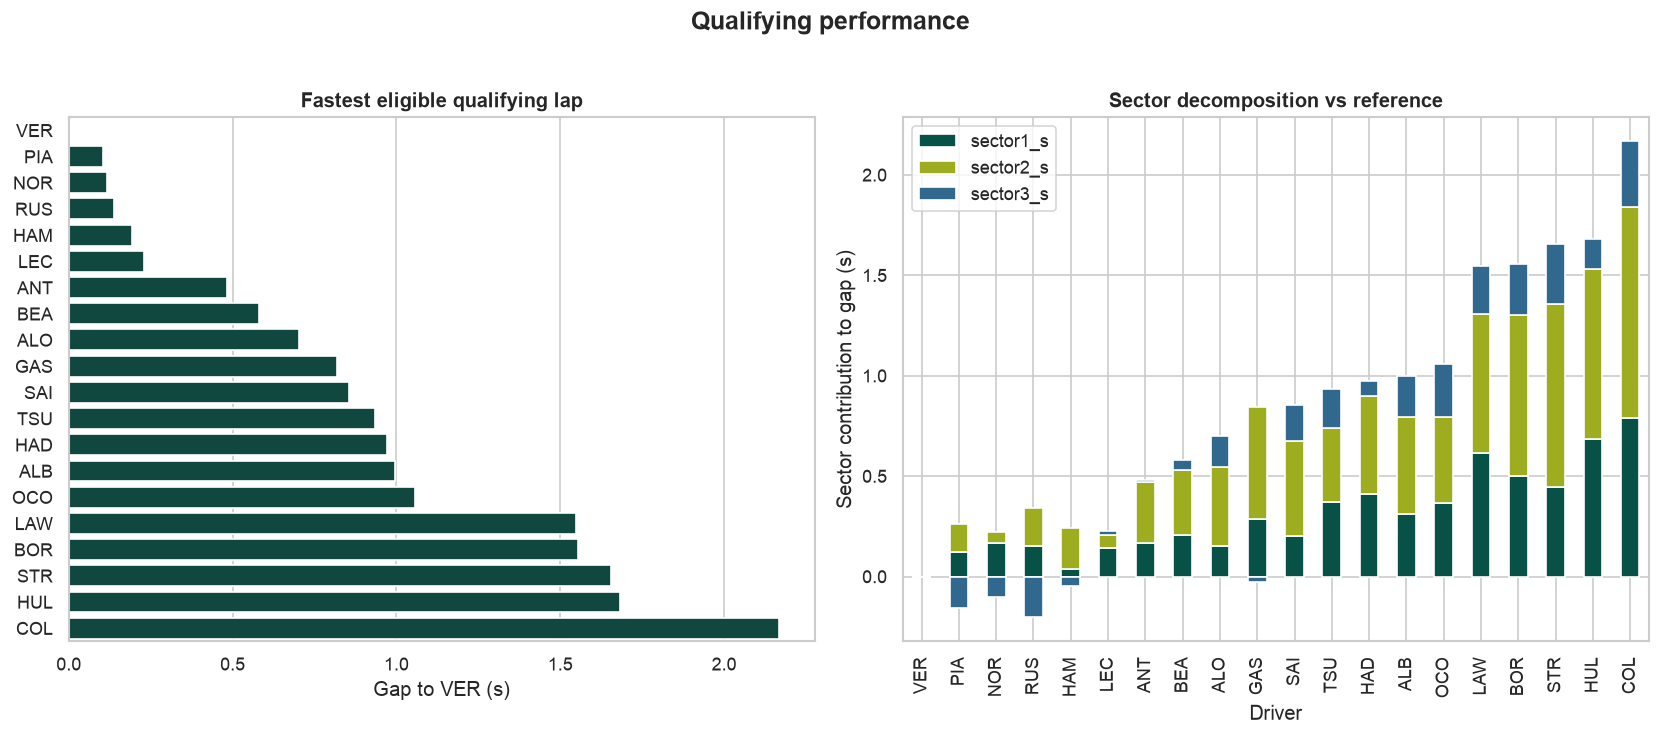

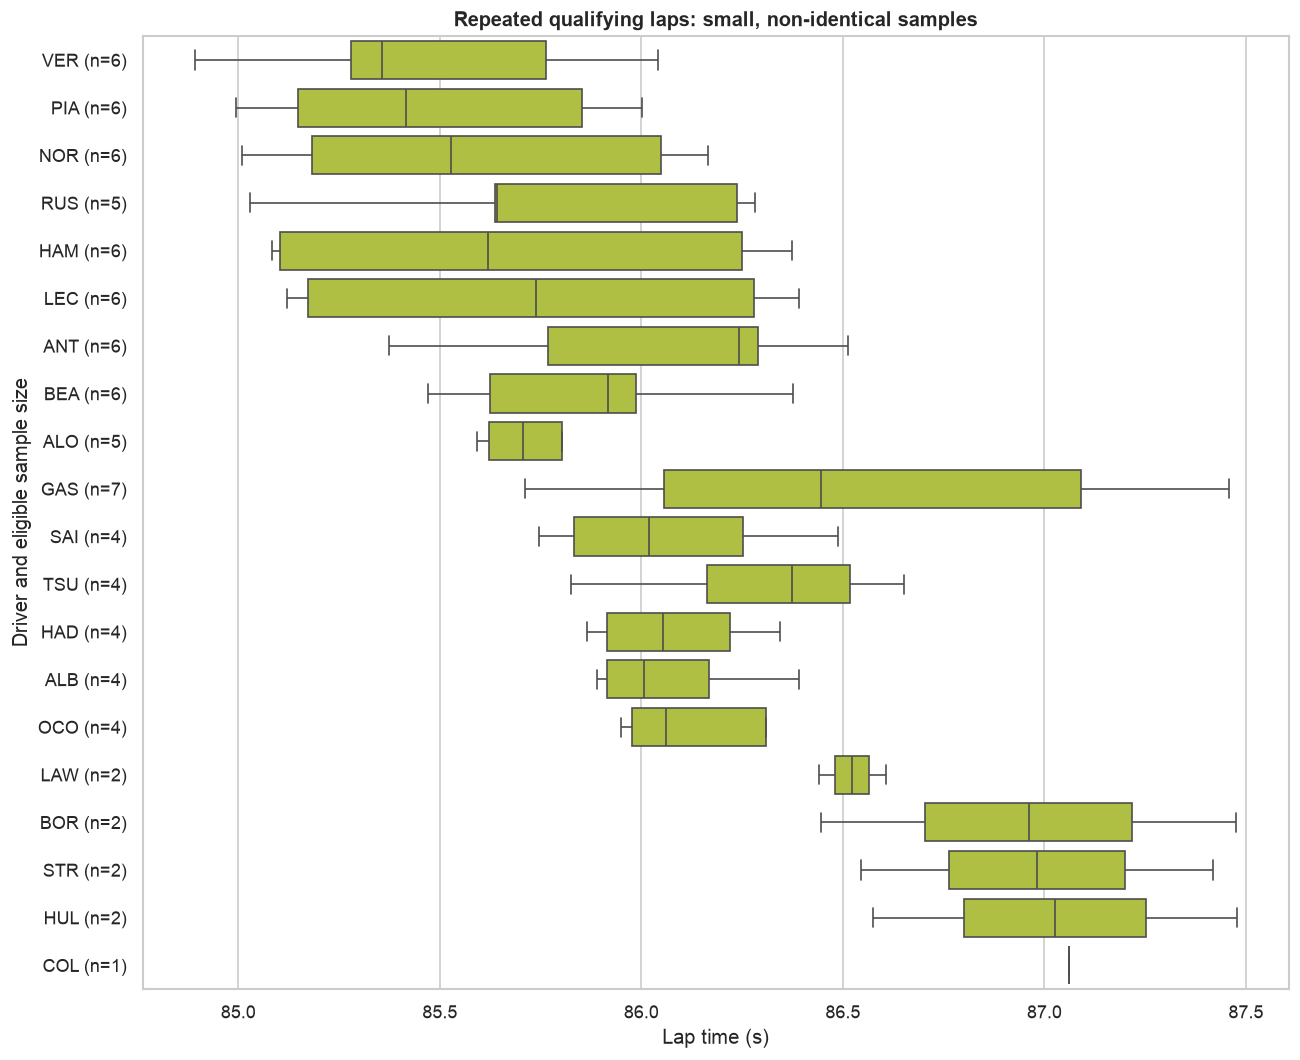

,driver,team,lap_s,gap_s,sector1_s,sector2_s,sector3_s,speed_trap_kmh
7120,VER,Red Bull Racing,84.892,0.000,27.493,33.973,23.426,323.0
7082,PIA,McLaren,84.995,0.103,27.615,34.113,23.267,319.0
7112,NOR,McLaren,85.010,0.118,27.659,34.027,23.324,318.0
7110,RUS,Mercedes,85.029,0.137,27.644,34.163,23.222,322.0
7045,HAM,Ferrari,85.084,0.192,27.528,34.179,23.377,322.0
7114,LEC,Ferrari,85.121,0.229,27.635,34.036,23.450,319.0
7109,ANT,Mercedes,85.374,0.482,27.658,34.279,23.437,321.0
7111,BEA,Haas F1 Team,85.471,0.579,27.698,34.297,23.476,319.0
7046,ALO,Aston Martin,85.593,0.701,27.645,34.365,23.583,322.0
7056,GAS,Alpine,85.711,0.819,27.777,34.533,23.401,324.0


In [5]:
q = laps[laps.session.eq('Qualifying') & laps.analysis_eligible].copy()
q = q[q.lap_s <= q.lap_s.min()*1.07]
best = q.sort_values('lap_s').drop_duplicates('driver').sort_values('lap_s').copy()
reference_driver = best.iloc[0].driver
best['gap_s'] = best.lap_s-best.lap_s.min()
fig,ax=plt.subplots(1,2,figsize=(14,6))
sns.barplot(data=best,x='gap_s',y='driver',ax=ax[0],color='#075147')
ax[0].set(xlabel=f'Gap to {reference_driver} (s)',ylabel='',title='Fastest eligible qualifying lap')
sectors=best.set_index('driver')[['sector1_s','sector2_s','sector3_s']]
sector_gaps=sectors-sectors.iloc[0]
sector_gaps.plot.bar(stacked=True,ax=ax[1],color=['#075147','#9EAD20','#31688E'])
ax[1].set(xlabel='Driver',ylabel='Sector contribution to gap (s)',title='Sector decomposition vs reference')
finish('Qualifying performance')
fig,ax=plt.subplots(figsize=(11,9))
sns.boxplot(data=q,y='driver',x='lap_s',order=best.driver,ax=ax,color='#BDD330',showfliers=False)
counts=q.groupby('driver').size()
ax.set_yticks(range(len(best)),[f'{d} (n={counts[d]})' for d in best.driver])
ax.set(ylabel='Driver and eligible sample size',xlabel='Lap time (s)',title='Repeated qualifying laps: small, non-identical samples')
plt.tight_layout();plt.show()
display(best[['driver','team','lap_s','gap_s','sector1_s','sector2_s','sector3_s','speed_trap_kmh']])

In [6]:
row=best.iloc[0]
display(Markdown(f"**Reading the comparison.** {row.driver} records the quickest eligible sampled lap at **{row.lap_s:.3f} s**. "
    f"The sector bars reconcile to the lap gap within the stated timing tolerance. The distribution view contains "
    f"{len(q)} eligible laps across {q.driver.nunique()} drivers; sample sizes and qualifying phases differ, so the box plots are descriptive."))

**Reading the comparison.** VER records the quickest eligible sampled lap at **84.892 s**. The sector bars reconcile to the lap gap within the stated timing tolerance. The distribution view contains 88 eligible laps across 20 drivers; sample sizes and qualifying phases differ, so the box plots are descriptive.

## 4. Distance-aligned telemetry and approximate track view

I retrieve car and location samples for the two quickest timed drivers. From eligible laps for those drivers, I reserve the quickest lap as test, the next as validation and the remaining laps as training. This is a deliberate fast-lap holdout, not a random sample; it tests selected representative fast laps. Qualifying timing is descriptive and never enters the race predictor.

Distance is obtained by trapezoidal integration of measured speed over the observed UTC time axis. I retain only in-lap samples and remove duplicate timestamps. Telemetry rarely lands exactly on the timing-line boundary, so the comparison covers a **common observed distance interval**, not an extrapolated full lap. Continuous channels are interpolated onto 10 m bins; brake and gear use the previous observed sample. Position is matched by nearest timestamp within 0.5 s. Missing matches remain null.

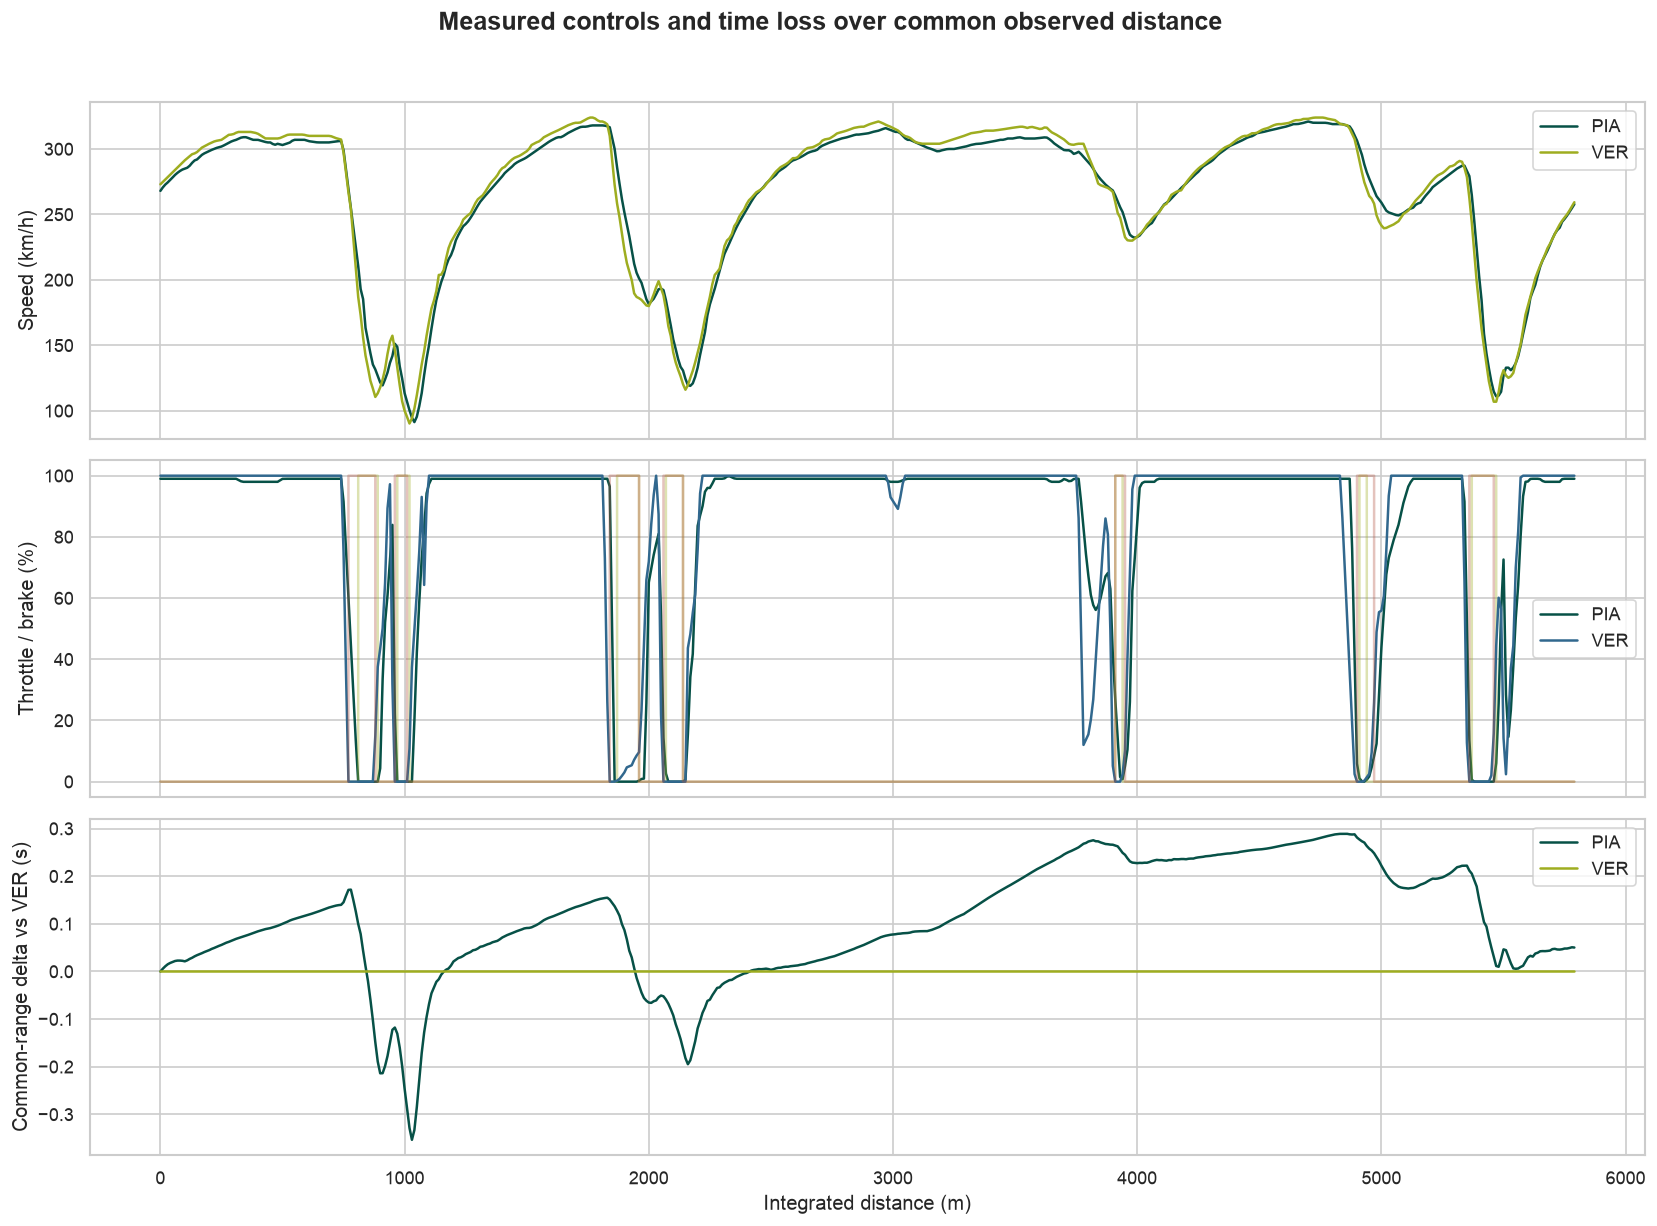

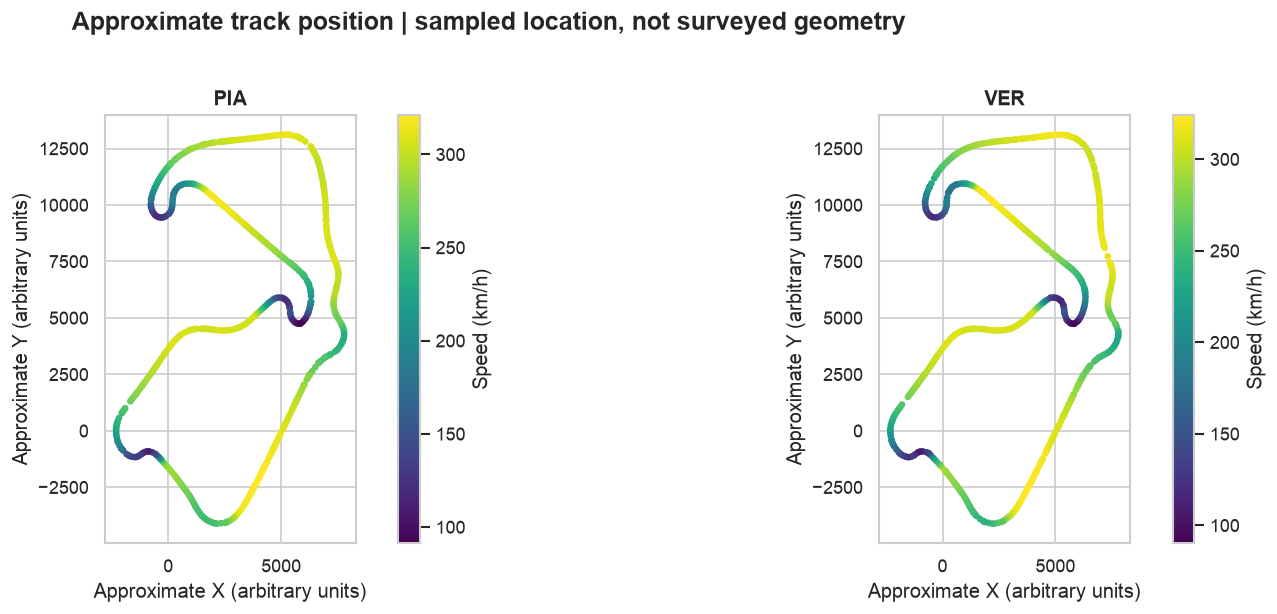

,common_elapsed_s,delta_common_s,lap_s,official_gap_s,endpoint_discrepancy_s
driver,,,,,
PIA,84.497161,0.050271,84.995,0.103,-0.052729
VER,84.446891,0.000000,84.892,0.000,0.000000


In [7]:
qsid=str(manifest.loc[manifest.session_name.eq('Qualifying'),'session_key'].iloc[0])
qd=raw[qsid]; car=pd.DataFrame(qd['car_data']); car['date']=utc(car.date)
position=pd.DataFrame(qd['location']); position['date']=utc(position.date)
telemetry_parts=[]
for number, samples in car.groupby('driver_number'):
    candidates=q[q.driver_number.eq(number)].sort_values('lap_s').head(7)
    for rank,(_,lap) in enumerate(candidates.iterrows()):
        t=samples[samples.date.between(lap.lap_start_utc,lap.lap_end_utc)].sort_values('date').drop_duplicates('date').copy()
        if len(t)<80: continue
        t['t_s']=(t.date-lap.lap_start_utc).dt.total_seconds()
        t=t.rename(columns={'speed':'speed_kmh','throttle':'throttle_pct','n_gear':'gear'})
        t['brake']=t.brake.gt(0).astype(int)
        dt=np.diff(t.t_s); v=t.speed_kmh.to_numpy()/3.6
        t['distance_m']=np.r_[0,np.cumsum((v[1:]+v[:-1])*.5*dt)]
        t['accel_observed_ms2']=np.gradient(savgol_filter(v,11,2),t.t_s)
        p=position[position.driver_number.eq(number)].sort_values('date')
        t=pd.merge_asof(t,p[['date','x','y']].rename(columns={'x':'x_approx','y':'y_approx'}),
                        on='date',direction='nearest',tolerance=pd.Timedelta(seconds=.5))
        for k in ['driver','team','lap_key','lap_number','lap_s','event','year','session','session_id']:
            t[k]=lap[k]
        t['split']='test' if rank==0 else 'validation' if rank==1 else 'train'
        telemetry_parts.append(t)
telemetry=pd.concat(telemetry_parts,ignore_index=True)
telemetry=telemetry[telemetry.speed_kmh.gt(0)].copy()
assert not telemetry.duplicated(['lap_key','t_s']).any()
for _,g in telemetry.groupby('lap_key'):
    assert (np.diff(g.t_s)>0).all() and (np.diff(g.distance_m)>0).all()
selected=telemetry[telemetry.split.eq('test')]
lo=max(g.distance_m.min() for _,g in selected.groupby('lap_key'))
hi=min(g.distance_m.max() for _,g in selected.groupby('lap_key'))
grid=np.arange(np.ceil(lo/10)*10,np.floor(hi/10)*10+1,10)
aligned=[]
for key,g in selected.groupby('lap_key'):
    g=g.sort_values('distance_m'); a=pd.DataFrame({'distance_m':grid})
    for c in ['speed_kmh','throttle_pct','t_s','accel_observed_ms2','x_approx','y_approx']:
        valid=g[['distance_m',c]].dropna()
        a[c]=np.interp(grid,valid.distance_m,valid[c],left=np.nan,right=np.nan)
    ix=np.searchsorted(g.distance_m,grid,side='right')-1
    for c in ['brake','gear']: a[c]=g[c].to_numpy()[ix]
    for c in ['lap_key','driver','team','lap_number','lap_s','event','year','session','session_id','split']:a[c]=g[c].iloc[0]
    a['elapsed_common_s']=a.t_s-a.t_s.iloc[0]
    aligned.append(a)
aligned=pd.concat(aligned,ignore_index=True)
telemetry_reference=selected.groupby('driver').lap_s.first().idxmin()
ref=aligned[aligned.driver.eq(telemetry_reference)].set_index('distance_m').elapsed_common_s
aligned['delta_common_s']=aligned.elapsed_common_s-aligned.distance_m.map(ref)
aligned['mean_speed_kmh']=aligned.groupby('lap_key').speed_kmh.transform('mean')
fig,ax=plt.subplots(3,1,figsize=(14,10),sharex=True)
for driver,g in aligned.groupby('driver'):
    ax[0].plot(g.distance_m,g.speed_kmh,label=driver)
    ax[1].plot(g.distance_m,g.throttle_pct,label=driver)
    ax[1].step(g.distance_m,g.brake*100,alpha=.35,where='post')
    ax[2].plot(g.distance_m,g.delta_common_s,label=driver)
for axis in ax:axis.legend()
ax[0].set(ylabel='Speed (km/h)');ax[1].set(ylabel='Throttle / brake (%)')
ax[2].set(xlabel='Integrated distance (m)',ylabel=f'Common-range delta vs {telemetry_reference} (s)')
finish('Measured controls and time loss over common observed distance')
fig,ax=plt.subplots(1,2,figsize=(14,5))
for axis,(driver,g) in zip(ax,aligned.groupby('driver')):
    p=axis.scatter(g.x_approx,g.y_approx,c=g.speed_kmh,s=9,cmap='viridis')
    axis.set_aspect('equal');axis.set(title=driver,xlabel='Approximate X (arbitrary units)',ylabel='Approximate Y (arbitrary units)')
    plt.colorbar(p,ax=axis,label='Speed (km/h)')
finish('Approximate track position | sampled location, not surveyed geometry')
endpoint=aligned.groupby('driver').agg(common_elapsed_s=('elapsed_common_s','max'),delta_common_s=('delta_common_s','last'),lap_s=('lap_s','first'))
endpoint['official_gap_s']=endpoint.lap_s-endpoint.loc[telemetry_reference,'lap_s']
endpoint['endpoint_discrepancy_s']=endpoint.delta_common_s-endpoint.official_gap_s
display(endpoint)

In [8]:
# Time-weighted mean speed over the observed in-lap samples.
means = {
    key: np.trapezoid(g.speed_kmh, g.t_s) / (g.t_s.iloc[-1] - g.t_s.iloc[0])
    for key, g in telemetry.sort_values('t_s').groupby('lap_key')
}
laps['mean_observed_speed_kmh'] = laps.lap_key.map(means)
speed_summary = best[['driver', 'speed_trap_kmh', 'lap_key']].copy()
speed_summary['mean_observed_speed_kmh'] = speed_summary.lap_key.map(means)
display(speed_summary.drop(columns='lap_key').dropna(subset=['mean_observed_speed_kmh']).round(3))

,driver,speed_trap_kmh,mean_observed_speed_kmh
7120,VER,323.0,246.838
7082,PIA,319.0,246.732


The endpoint table is a reconciliation check, not a forced correction: independently integrated distance, missing timing-line samples and different travelled distances can make the common-range delta disagree with the official lap gap. I retain that discrepancy. Mean speed in this grid is distance-sampled; the full observed-lap time-weighted mean is calculated separately below. Neither should be confused with the source speed trap.

## 5. Tyres, weather and race pace

Race pace is observational. Tyre compound, fuel burn, traffic, weather and driver strategy change together. I compare eligible laps within an event and show excluded laps on timelines rather than interpreting a regression slope as a causal degradation rate. Event-median normalisation is a retrospective display field only; it is not a prediction feature.

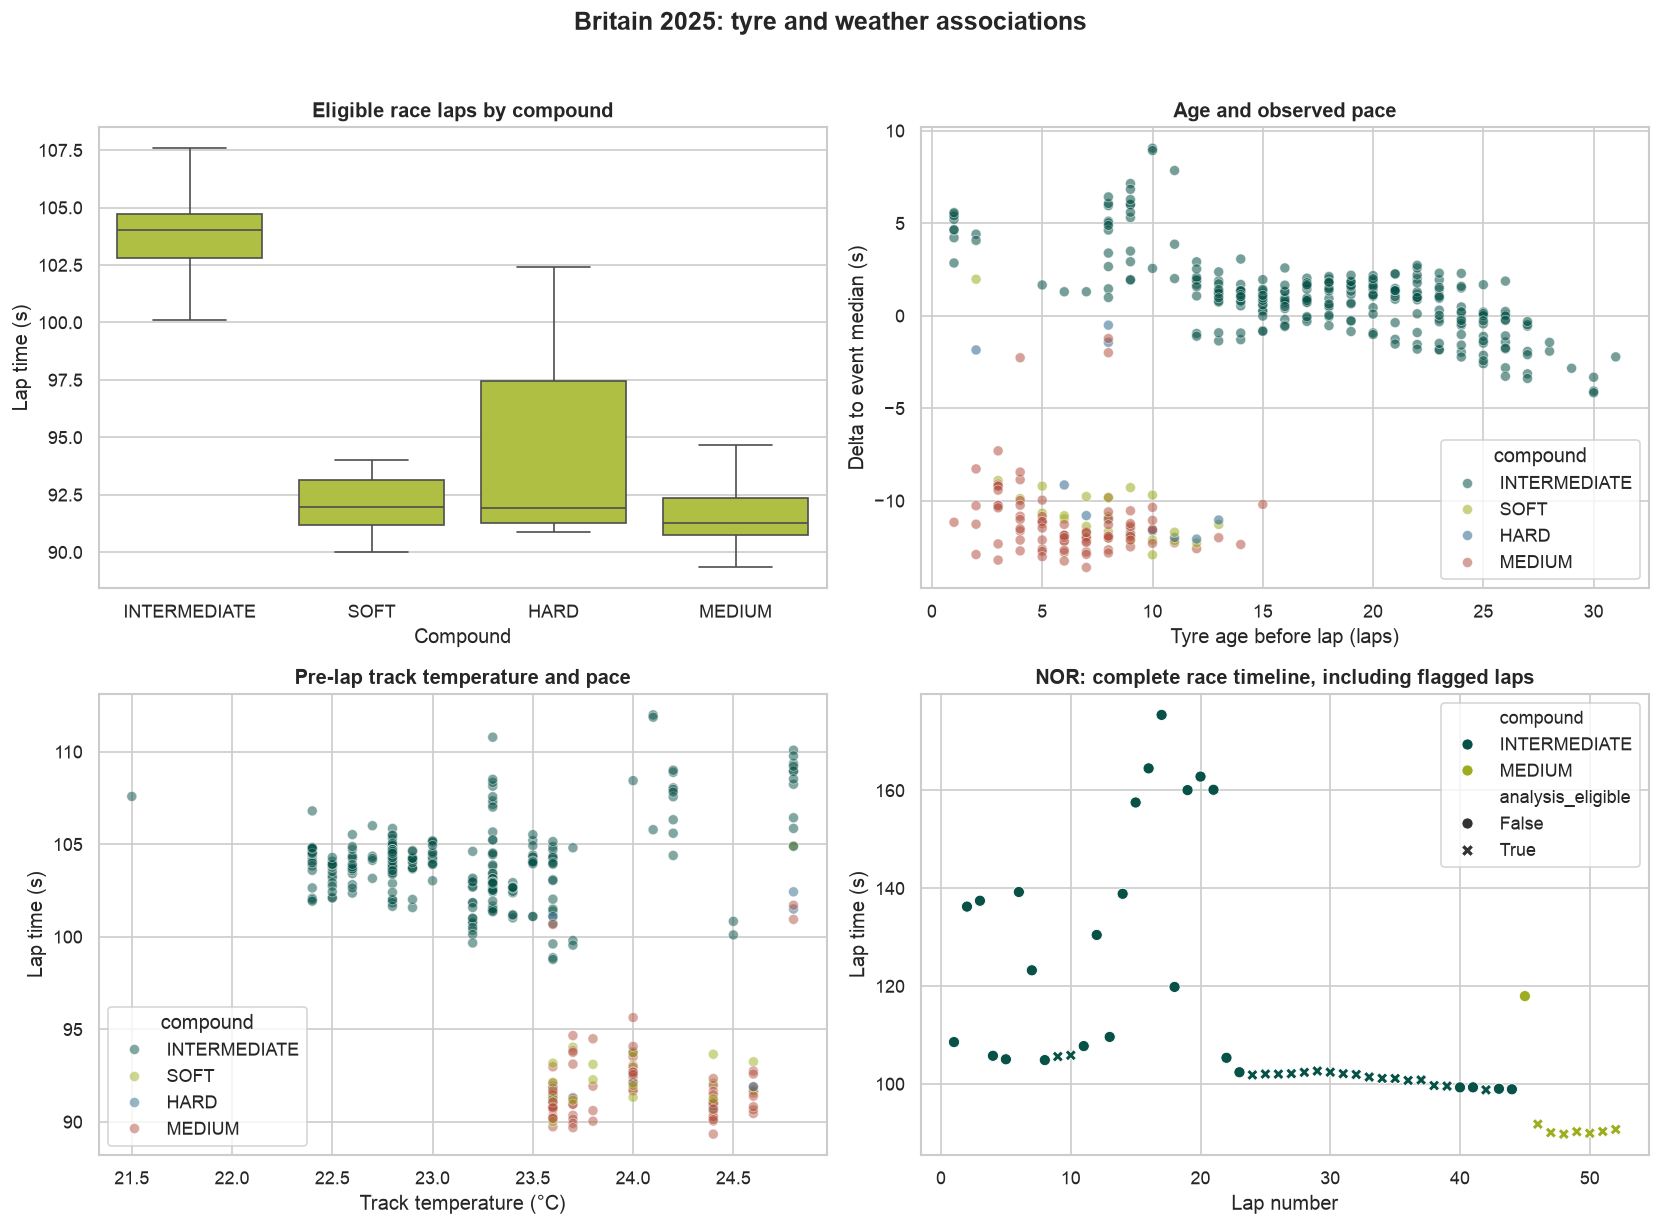

n  median_lap_s
year event       compound                       
2024 Catalunya   HARD          345        79.867
                 MEDIUM        401        80.849
                 SOFT          475        81.217
     Silverstone HARD           39        89.872
                 INTERMEDIATE  189       103.157
                 MEDIUM        481        92.722
                 SOFT          160        91.186
     Spielberg   HARD          631        71.048
                 MEDIUM        578        71.218
                 SOFT            5        68.072
2025 Catalunya   HARD            5        78.081
                 MEDIUM        457        80.959
                 SOFT          528        81.458
     Silverstone HARD           11        91.926
                 INTERMEDIATE  264       104.005
                 MEDIUM         87        91.273
                 SOFT           23        91.961
     Spielberg   HARD          397        70.350
                 MEDIUM        513        70.908
                 SOFT           50        71.042

In [9]:
race=laps[laps.session.eq('Race')].copy()
clean=race[race.analysis_eligible].copy()
event_medians=clean.groupby('session_id').lap_s.median()
race['event_normalised_pace_s']=race.lap_s-race.session_id.map(event_medians)
laps['event_normalised_pace_s']=laps.lap_s-laps.session_id.map(event_medians)
view=race[(race.year==2025)&race.event.eq('Silverstone')]
cv=view[view.analysis_eligible]
fig,ax=plt.subplots(2,2,figsize=(14,10))
sns.boxplot(data=cv,x='compound',y='lap_s',ax=ax[0,0],color='#BDD330',showfliers=False)
ax[0,0].set(title='Eligible race laps by compound',ylabel='Lap time (s)',xlabel='Compound')
sns.scatterplot(data=cv,x='tyre_age_start_laps',y='event_normalised_pace_s',hue='compound',ax=ax[0,1],alpha=.55)
ax[0,1].set(title='Age and observed pace',xlabel='Tyre age before lap (laps)',ylabel='Delta to event median (s)')
sns.scatterplot(data=cv,x='track_temp_c',y='lap_s',hue='compound',ax=ax[1,0],alpha=.5)
ax[1,0].set(title='Pre-lap track temperature and pace',xlabel='Track temperature (°C)',ylabel='Lap time (s)')
focus=view[view.driver.eq('NOR')]
sns.scatterplot(data=focus,x='lap_number',y='lap_s',hue='compound',style='analysis_eligible',ax=ax[1,1],s=45)
ax[1,1].set(title='NOR: complete race timeline, including flagged laps',xlabel='Lap number',ylabel='Lap time (s)')
finish('Britain 2025: tyre and weather associations')
display(clean.groupby(['year','event','compound']).agg(n=('lap_s','size'),median_lap_s=('lap_s','median')).round(3))

Britain's changing conditions make it a demanding transfer test. The same compound can appear at different stages of a wet or drying race, and excluded interruption laps affect sample coverage. The broad lap-time spread is a reason to show conditions and flags alongside any pace comparison.

## 6. Pre-lap prediction with whole-event holdouts

I predict lap time using only the driver/team, circuit, lap number, starting tyre age/compound, backward-matched weather and a driver's earlier completed eligible laps. The rolling median uses only the preceding three eligible laps, shifted by one; the first three eligible laps per driver/session are excluded. Earlier observations within a held-out race are available sequentially, but no model is refitted on that event. This is an **online one-lap-ahead task**, not a forecast of the whole race before its start.

The learned target is residual lap time relative to that prior-three-lap median. This reduces circuit scale differences. I compare a training-only circuit median, the sequential prior-lap median, ridge regression and random forest. Hyperparameters are chosen on Spain 2025 alone, then frozen for the two untouched test events. Eligibility screening defines the target population after the lap; it is not itself predicted. Results therefore describe eligible completed laps and do not measure interruption detection.

In [10]:
model_data=clean.sort_values(['session_id','driver_number','lap_number']).copy()
model_data['prior_lap_median_s']=model_data.groupby(['session_id','driver_number']).lap_s.transform(
    lambda s:s.shift(1).rolling(3,min_periods=3).median())
model_data=model_data.dropna(subset=['prior_lap_median_s','tyre_age_start_laps','compound']).copy()
features=['event','driver','team','compound','lap_number','tyre_age_start_laps','track_temp_c',
          'air_temp_c','rainfall','humidity_pct','wind_speed_ms','prior_lap_median_s']
cat=['event','driver','team','compound']; num=[c for c in features if c not in cat]
assert not set(features)&{'lap_s','sector1_s','sector2_s','sector3_s','speed_trap_kmh','event_normalised_pace_s'}
train=model_data[model_data.split.eq('train')]; val=model_data[model_data.split.eq('validation')]; test=model_data[model_data.split.eq('test')]
assert set(train.session_id).isdisjoint(val.session_id) and set(train.session_id).isdisjoint(test.session_id)
assert set(val.session_id).isdisjoint(test.session_id)
assert train.lap_start_utc.max()<val.lap_start_utc.min()<test.lap_start_utc.min()
def preprocessing():
    return ColumnTransformer([('num',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),num),
        ('cat',make_pipeline(SimpleImputer(strategy='most_frequent'),OneHotEncoder(handle_unknown='ignore',sparse_output=False)),cat)])
ytrain=train.lap_s-train.prior_lap_median_s
candidates={}
for alpha in [1.,10.,100.]:
    name=f'Ridge alpha={alpha:g}';candidates[name]=make_pipeline(preprocessing(),Ridge(alpha=alpha))
for leaf in [5,20]:
    name=f'Random forest leaf={leaf}';candidates[name]=make_pipeline(preprocessing(),
        RandomForestRegressor(n_estimators=160,min_samples_leaf=leaf,max_depth=12,random_state=SEED,n_jobs=-1))
validation_rows=[]
for name,model in candidates.items():
    model.fit(train[features],ytrain)
    pred=val.prior_lap_median_s+model.predict(val[features])
    validation_rows.append({'model':name,**scores(val.lap_s,pred)})
validation_scores=pd.DataFrame(validation_rows).sort_values('mae')
chosen_ridge=validation_scores[validation_scores.model.str.startswith('Ridge')].iloc[0].model
chosen_rf=validation_scores[validation_scores.model.str.startswith('Random')].iloc[0].model
chosen=validation_scores.iloc[0].model
selected_models={chosen_ridge:candidates[chosen_ridge],chosen_rf:candidates[chosen_rf]}
training_circuit_median=train.groupby('event').lap_s.median()
pred_parts=[];metric_rows=[]
for split,part in [('validation',val),('test',test)]:
    predictions={'Training circuit median':part.event.map(training_circuit_median).fillna(train.lap_s.median()).to_numpy(),
                 'Prior 3-lap median':part.prior_lap_median_s.to_numpy()}
    predictions.update({name:part.prior_lap_median_s.to_numpy()+model.predict(part[features]) for name,model in selected_models.items()})
    for name,values in predictions.items():
        p=part[['lap_key','session_id','year','event','session','driver','team','lap_number','compound','tyre_age_start_laps','lap_s','split']].copy()
        p['actual_s']=part.lap_s;p['predicted_s']=values;p['residual_s']=p.predicted_s-p.actual_s;p['model']=name
        pred_parts.append(p)
        metric_rows.append(dict(task='lap_prediction',model=name,split=split,unit='s',ground_truth='Observed eligible lap time',**scores(part.lap_s,values)))
predictions=pd.concat(pred_parts,ignore_index=True)
metrics=pd.DataFrame(metric_rows)
display(model_data.groupby(['split','year','event']).size().rename('prediction_laps').to_frame())
display(validation_scores.round(4));display(metrics.round(4))

prediction_laps
split      year event                       
test       2025 Silverstone              336
                Spielberg                909
train      2024 Catalunya               1161
                Silverstone              812
                Spielberg               1154
validation 2025 Catalunya                933

,model,mae,rmse,max_abs_error,n
3,Random forest leaf=5,0.4972,0.7594,8.4460,933
4,Random forest leaf=20,0.5050,0.7806,8.4811,933
0,Ridge alpha=1,1.2853,1.4864,9.3838,933
2,Ridge alpha=100,1.4285,1.5939,9.7922,933
1,Ridge alpha=10,3.1121,3.2029,11.3101,933


,task,model,split,unit,ground_truth,mae,rmse,max_abs_error,n
0,lap_prediction,Training circuit median,validation,s,Observed eligible lap time,1.1244,1.4429,10.0300,933
1,lap_prediction,Prior 3-lap median,validation,s,Observed eligible lap time,0.5699,0.8944,8.3520,933
2,lap_prediction,Ridge alpha=1,validation,s,Observed eligible lap time,1.2853,1.4864,9.3838,933
3,lap_prediction,Random forest leaf=5,validation,s,Observed eligible lap time,0.4972,0.7594,8.4460,933
4,lap_prediction,Training circuit median,test,s,Observed eligible lap time,2.6255,4.6006,17.8855,1245
5,lap_prediction,Prior 3-lap median,test,s,Observed eligible lap time,0.7276,1.6101,10.5240,1245
6,lap_prediction,Ridge alpha=1,test,s,Observed eligible lap time,0.8913,1.3555,9.0289,1245
7,lap_prediction,Random forest leaf=5,test,s,Observed eligible lap time,1.0477,1.9714,10.3748,1245


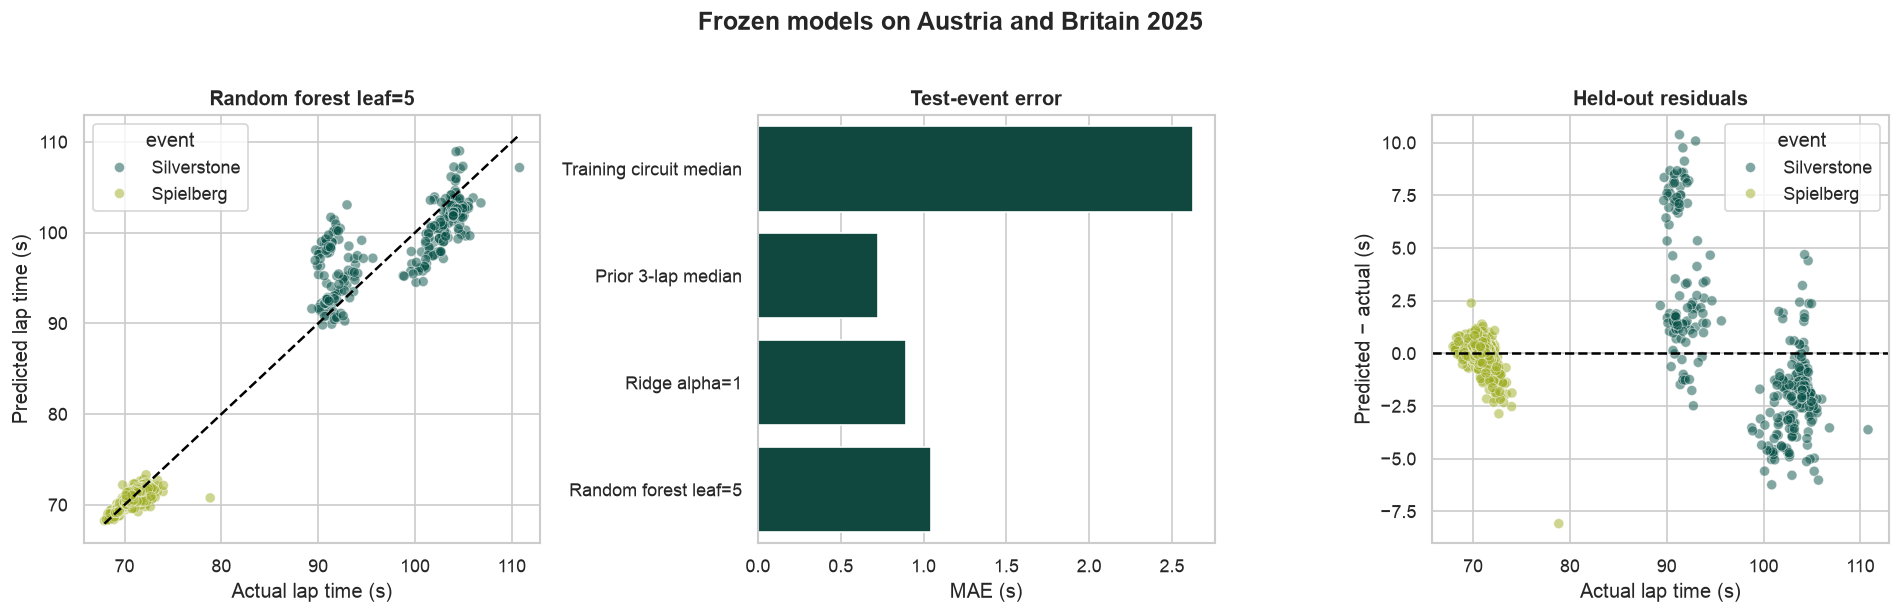

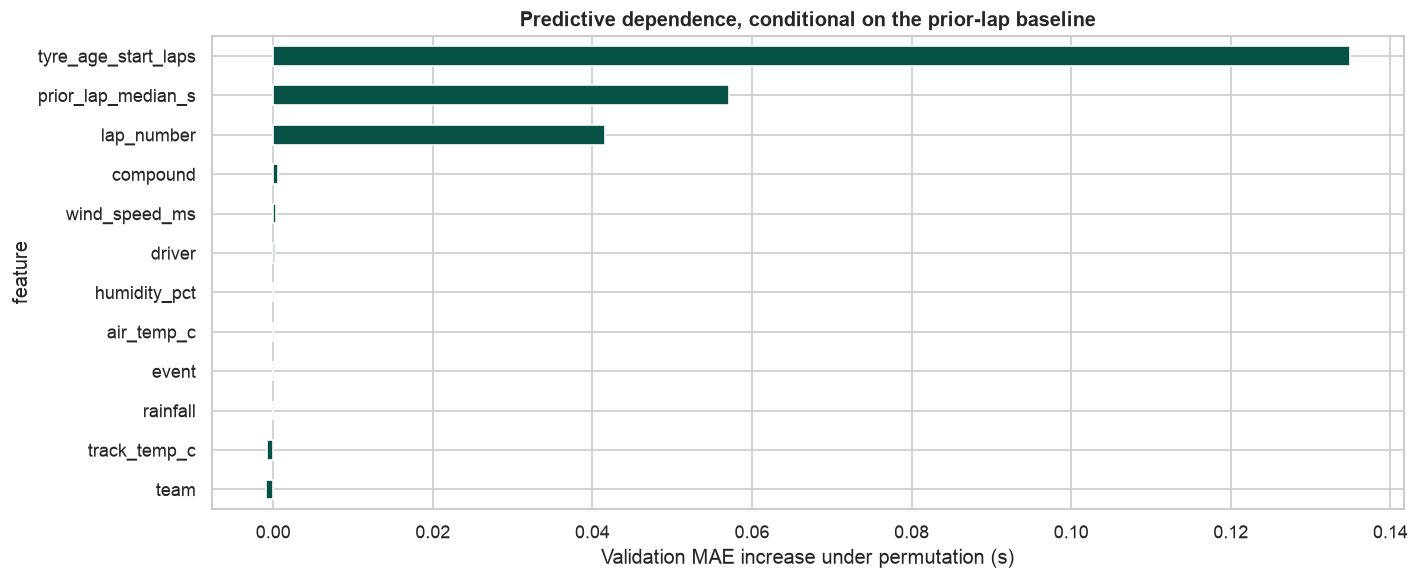

,mae,rmse,max_abs_error,n
event,,,,
Silverstone,2.912,3.673,10.375,336.0
Spielberg,0.359,0.580,8.081,909.0


**Result.** Validation selected **Random forest leaf=5**. The lowest test MAE among all reported benchmarks belongs to **Prior 3-lap median**, at **0.728 s**. The comparison is reported even if a simple baseline wins. Permutation importance measures model dependence, not a causal effect; correlated predictors can share or mask importance.

In [11]:
p=predictions[predictions.split.eq('test') & predictions.model.eq(chosen)]
fig,ax=plt.subplots(1,3,figsize=(16,5))
sns.scatterplot(data=p,x='actual_s',y='predicted_s',hue='event',ax=ax[0],alpha=.5)
limits=[min(p.actual_s.min(),p.predicted_s.min()),max(p.actual_s.max(),p.predicted_s.max())]
ax[0].plot(limits,limits,'k--');ax[0].set(title=chosen,xlabel='Actual lap time (s)',ylabel='Predicted lap time (s)')
sns.barplot(data=metrics[(metrics.task=='lap_prediction')&(metrics.split=='test')],x='mae',y='model',ax=ax[1],color='#075147')
ax[1].set(title='Test-event error',xlabel='MAE (s)',ylabel='')
sns.scatterplot(data=p,x='actual_s',y='residual_s',hue='event',ax=ax[2],alpha=.5)
ax[2].axhline(0,color='black',ls='--');ax[2].set(title='Held-out residuals',xlabel='Actual lap time (s)',ylabel='Predicted − actual (s)')
finish('Frozen models on Austria and Britain 2025')
importance_result=permutation_importance(selected_models[chosen],val[features],val.lap_s-val.prior_lap_median_s,
    scoring='neg_mean_absolute_error',n_repeats=8,random_state=SEED,n_jobs=1)
importance=pd.DataFrame({'feature':features,'importance_mae_increase_s':importance_result.importances_mean,
                          'importance_std_s':importance_result.importances_std})
importance['model']=chosen;importance['split']='validation';importance['task']='lap_prediction'
importance.sort_values('importance_mae_increase_s').plot.barh(x='feature',y='importance_mae_increase_s',legend=False,color='#075147')
plt.xlabel('Validation MAE increase under permutation (s)');plt.title('Predictive dependence, conditional on the prior-lap baseline');plt.tight_layout();plt.show()
display(p.groupby('event').apply(lambda g:pd.Series(scores(g.actual_s,g.predicted_s)),include_groups=False).round(3))
best_test=metrics[(metrics.task=='lap_prediction')&(metrics.split=='test')].sort_values('mae').iloc[0]
display(Markdown(f"**Result.** Validation selected **{chosen}**. The lowest test MAE among all reported benchmarks belongs to "
    f"**{best_test.model}**, at **{best_test.mae:.3f} s**. The comparison is reported even if a simple baseline wins. "
    "Permutation importance measures model dependence, not a causal effect; correlated predictors can share or mask importance."))

## 7. Simplified longitudinal dynamics

I use the two-state model below, integrated in **time** with measured controls:

\[
\dot v=a_T u_T-a_B u_B-k_Dv^2-a_R,\qquad \dot s=v.
\]

Speed is converted from km/h to m/s. Throttle is a fraction; brake is a switch, not pressure. All four fitted coefficients are non-negative effective responses rather than measured powertrain, drag or braking specifications.

I form non-overlapping 5-second windows inside each selected qualifying lap, reject time gaps above 0.75 s, and reset each window to measured initial speed. Training, validation and test laps are disjoint. Windows cover the whole circuit; without reliable curvature/steering data I do not claim they are verified straights. Cornering is consequently an expected failure regime. I fit integrated speed, not its noisy derivative, with bounded least squares and a robust loss. A constant-initial-speed baseline uses the same resets. Validation selects the robust-loss scale from 1 and 3 m/s before the held-out laps are scored.

For the display derivative, measured speed is smoothed with an 11-sample quadratic Savitzky–Golay filter. This centred filter is retrospective and is never used as a pre-lap predictor or simulator input.

,parameter,value,unit,at_lower_bound
0,aT,1.695700e+01,m/s²,False
1,aB,1.048107e+01,m/s²,False
2,kD,2.250404e-03,1/m,False
3,aR,3.323962e-16,m/s²,True


Converged: True Selected robust scale: 3.0 Jacobian condition: 74475.69


,task,model,split,unit,ground_truth,mae,rmse,max_abs_error,n
8,physics_speed,Longitudinal physics,validation,m/s,Measured speed,2.1006,3.2242,16.0949,528
9,physics_speed,Constant speed,validation,m/s,Measured speed,11.1285,16.3163,50.5556,528
10,physics_speed,Longitudinal physics,test,m/s,Measured speed,2.2184,3.4740,18.1118,505
11,physics_speed,Constant speed,test,m/s,Measured speed,12.4230,17.5162,51.1111,505


,mae,rmse,max_abs_error,n
regime,,,,
braking,4.814,6.801,18.112,78.0
high_throttle,1.370,1.711,5.206,322.0
partial_or_lift,2.892,3.835,11.465,105.0


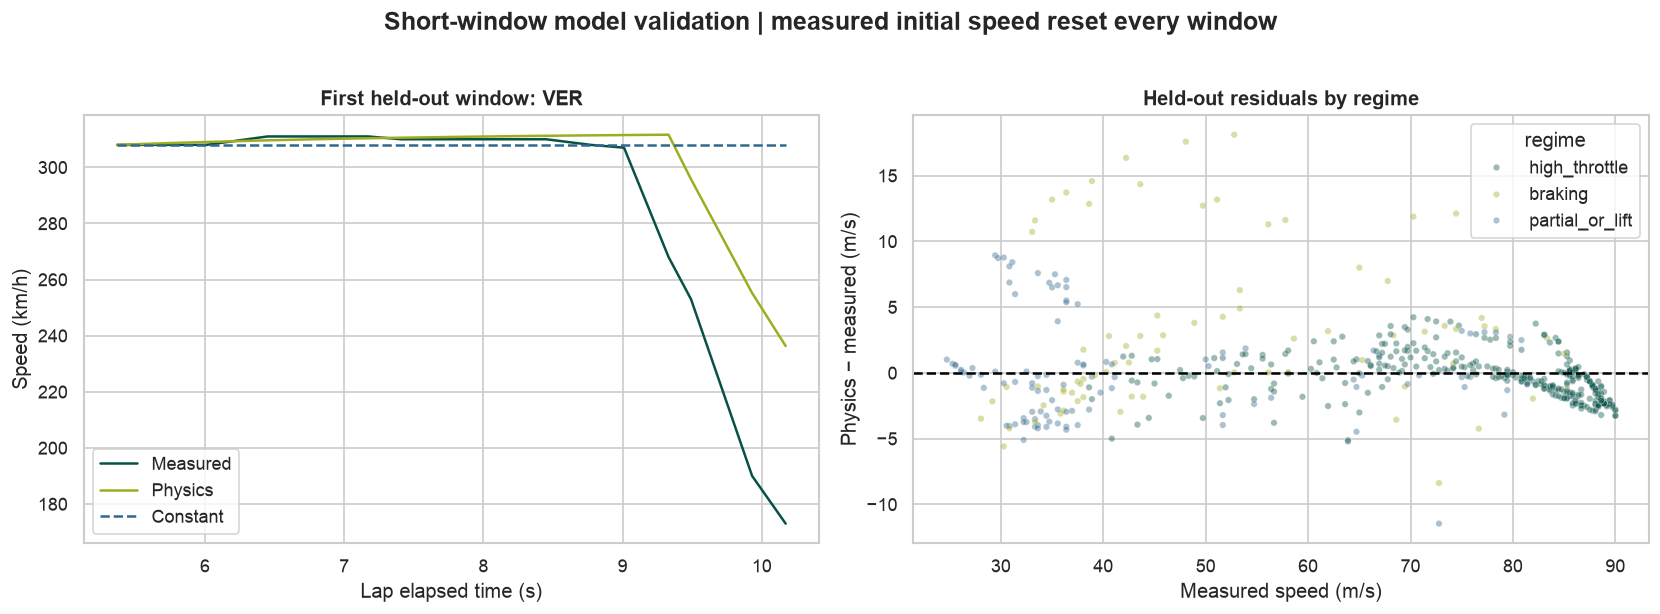

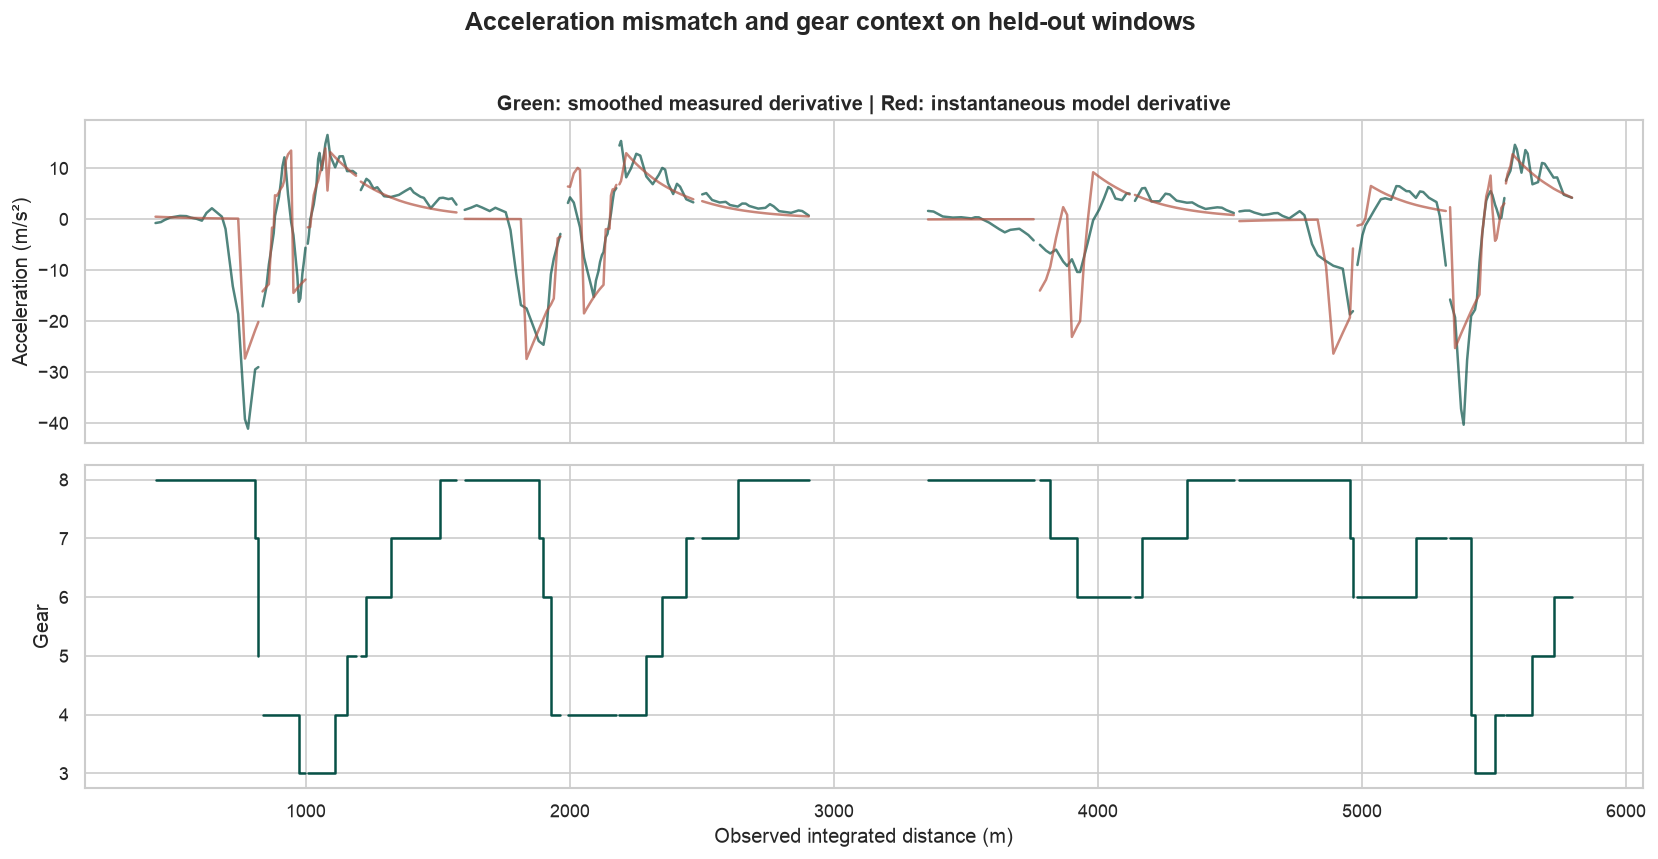

In [12]:
def simulate(theta,v0,throttle,brake,t):
    aT,aB,kD,aR=theta
    v=np.zeros(len(t));v[0]=v0
    for i,h in enumerate(np.diff(t)):
        a=aT*throttle[i]-aB*brake[i]-kD*v[i]**2-aR
        v[i+1]=max(0.,v[i]+h*a)
    distance=np.r_[0.,np.cumsum((v[:-1]+v[1:])*.5*np.diff(t))]
    return v,distance
windows=[]
for key,g in telemetry.groupby('lap_key'):
    g=g.sort_values('t_s').copy();g['window_bin']=((g.t_s-g.t_s.min())//5).astype(int)
    for index,w in g.groupby('window_bin'):
        if len(w)<10 or w.t_s.iloc[-1]-w.t_s.iloc[0]<3 or np.diff(w.t_s).max()>.75: continue
        w=w.copy();w['window_id']=f'{key}_w{index}';windows.append(w)
assert len(windows)>10
train_windows=[w for w in windows if w.split.iloc[0]=='train']
val_windows=[w for w in windows if w.split.iloc[0]=='validation']
test_windows=[w for w in windows if w.split.iloc[0]=='test']
assert train_windows and val_windows and test_windows
assert set(w.lap_key.iloc[0] for w in train_windows).isdisjoint(w.lap_key.iloc[0] for w in test_windows)
def speed_prediction(theta,w):
    return simulate(theta,w.speed_kmh.iloc[0]/3.6,w.throttle_pct.to_numpy()/100,w.brake.to_numpy(),w.t_s.to_numpy())[0]
def residuals(theta,collection):
    return np.concatenate([speed_prediction(theta,w)[1:]-w.speed_kmh.to_numpy()[1:]/3.6 for w in collection])
fits={scale:least_squares(residuals,[10.,15.,.001,.2],args=(train_windows,),bounds=([0,0,0,0],[40,50,.02,10]),
                         loss='soft_l1',f_scale=scale,x_scale='jac',max_nfev=300) for scale in [1.,3.]}
selected_scale=min(fits,key=lambda scale:np.mean(abs(residuals(fits[scale].x,val_windows))))
fit=fits[selected_scale];theta=fit.x
parameter_table=pd.DataFrame({'parameter':['aT','aB','kD','aR'],'value':theta,
                             'unit':['m/s²','m/s²','1/m','m/s²'], 'at_lower_bound':theta<1e-8})
condition=np.linalg.cond(fit.jac)
display(parameter_table);print('Converged:',fit.success,'Selected robust scale:',selected_scale,'Jacobian condition:',round(condition,2))
physics_parts=[]
for w in windows:
    p=w[['window_id','lap_key','session_id','year','event','session','driver','team','lap_number','split','t_s','distance_m','speed_kmh','throttle_pct','brake','gear','accel_observed_ms2']].copy()
    v=speed_prediction(theta,w);p['speed_observed_ms']=w.speed_kmh.to_numpy()/3.6
    p['speed_physics_ms']=v;p['speed_constant_ms']=v[0]
    p['accel_physics_ms2']=theta[0]*p.throttle_pct/100-theta[1]*p.brake-theta[2]*v**2-theta[3]
    p['speed_residual_ms']=v-p.speed_observed_ms
    p['regime']=np.select([p.brake.gt(0),p.throttle_pct.ge(90)],['braking','high_throttle'],default='partial_or_lift')
    p['initial_sample']=False;p.loc[p.index[0],'initial_sample']=True
    physics_parts.append(p)
physics=pd.concat(physics_parts,ignore_index=True)
for split in ['validation','test']:
    part=physics[physics.split.eq(split)&~physics.initial_sample]
    for name,col in [('Longitudinal physics','speed_physics_ms'),('Constant speed','speed_constant_ms')]:
        metric_rows.append(dict(task='physics_speed',model=name,split=split,unit='m/s',ground_truth='Measured speed',**scores(part.speed_observed_ms,part[col])))
physics_test=physics[physics.split.eq('test')&~physics.initial_sample]
display(pd.DataFrame(metric_rows).query("task=='physics_speed'").round(4))
display(physics_test.groupby('regime').apply(lambda g:pd.Series(scores(g.speed_observed_ms,g.speed_physics_ms)),include_groups=False).round(3))
fig,ax=plt.subplots(1,2,figsize=(14,5))
example=physics_test.window_id.iloc[0];ex=physics[physics.window_id.eq(example)]
ax[0].plot(ex.t_s,ex.speed_observed_ms*3.6,label='Measured')
ax[0].plot(ex.t_s,ex.speed_physics_ms*3.6,label='Physics');ax[0].plot(ex.t_s,ex.speed_constant_ms*3.6,'--',label='Constant')
ax[0].set(title=f'First held-out window: {ex.driver.iloc[0]}',xlabel='Lap elapsed time (s)',ylabel='Speed (km/h)');ax[0].legend()
sns.scatterplot(data=physics_test,x='speed_observed_ms',y='speed_residual_ms',hue='regime',ax=ax[1],alpha=.4,s=15)
ax[1].axhline(0,color='black',ls='--');ax[1].set(title='Held-out residuals by regime',xlabel='Measured speed (m/s)',ylabel='Physics − measured (m/s)')
finish('Short-window model validation | measured initial speed reset every window')
fig,ax=plt.subplots(2,1,figsize=(14,7),sharex=True)
for w in test_windows:
    if w.driver.iloc[0] != telemetry_reference: continue
    pred=speed_prediction(theta,w)
    ax[0].plot(w.distance_m,w.accel_observed_ms2,color='#075147',alpha=.7)
    acceleration=theta[0]*w.throttle_pct/100-theta[1]*w.brake-theta[2]*pred**2-theta[3]
    ax[0].plot(w.distance_m,acceleration,color='#B35443',alpha=.7)
    ax[1].step(w.distance_m,w.gear,where='post',color='#075147')
ax[0].set(ylabel='Acceleration (m/s²)',title='Green: smoothed measured derivative | Red: instantaneous model derivative')
ax[1].set(ylabel='Gear',xlabel='Observed integrated distance (m)');finish('Acceleration mismatch and gear context on held-out windows')

A good fit in these reset windows does not establish free-running full-lap accuracy. Bounds, a poorly conditioned Jacobian, and correlated throttle/speed/brake inputs can make coefficients weakly identifiable. I inspect sensitivity on validation windows only; a parameter perturbation changes all else equally and is not a statistical confidence interval. I perturb each parameter by 10% of its magnitude with small parameter-specific floors, clipping at zero. This also probes a coefficient fitted at its lower bound; simply multiplying zero would reveal nothing. Test errors aggregate serially correlated samples, so their sample count is not an independent experimental sample size.

In [13]:
sensitivity_rows=[]
for i,name in enumerate(parameter_table.parameter):
    for multiplier in [.9,1.1]:
        changed=theta.copy();floor=[1.,1.,.0001,.1][i]
        changed[i]=max(0.,theta[i]+(multiplier-1)*max(theta[i],floor))
        e=residuals(changed,val_windows)
        sensitivity_rows.append({'parameter':name,'multiplier':multiplier,'perturbed_value':changed[i],'validation_mae_ms':np.mean(abs(e)),
                                 'validation_rmse_ms':np.sqrt(np.mean(e**2))})
sensitivity=pd.DataFrame(sensitivity_rows)
display(sensitivity.round(5))
physics_summary=pd.DataFrame(metric_rows).query("task=='physics_speed' and split=='test'")
display(Markdown(f"**Measured outcome.** The longitudinal model's held-out speed MAE is "
    f"**{physics_summary.loc[physics_summary.model.eq('Longitudinal physics'),'mae'].iloc[0]:.3f} m/s**, versus "
    f"**{physics_summary.loc[physics_summary.model.eq('Constant speed'),'mae'].iloc[0]:.3f} m/s** for constant speed. "
    f"The test consists of {len(test_windows)} windows from {physics_test.lap_key.nunique()} laps. "
    "Unknown cornering forces, road slope, actual brake demand and gear-dependent power limit the model."))

,parameter,multiplier,perturbed_value,validation_mae_ms,validation_rmse_ms
0,aT,0.9,15.26130,2.74309,3.66268
1,aT,1.1,18.65270,3.16188,4.25004
2,aB,0.9,9.43296,2.15012,3.44038
3,aB,1.1,11.52917,2.09687,3.08016
4,kD,0.9,0.00203,2.89187,4.18542
5,kD,1.1,0.00248,2.45884,3.39376
6,aR,0.9,0.00000,2.10056,3.22416
7,aR,1.1,0.01000,2.09880,3.21961


**Measured outcome.** The longitudinal model's held-out speed MAE is **2.218 m/s**, versus **12.423 m/s** for constant speed. The test consists of 28 windows from 2 laps. Unknown cornering forces, road slope, actual brake demand and gear-dependent power limit the model.

## 8. Low-dimensional speed-profile representation

The longitudinal model is already a reduced-complexity two-state system. Separately, I use PCA to compress distance-aligned profiles at this circuit. PCA is fitted and centred on training laps only. Validation chooses among 2, 3 and 5 components when the training sample supports them; test profiles are reconstructed once. This is retrospective compression of an observed trace, not a forecast and not a formal reduction of a high-fidelity vehicle simulator.

,components,mae,rmse,max_abs_error,n
0,2,3.203,4.645,21.067,1154
1,3,3.013,4.459,23.601,1154
2,5,2.402,3.649,19.629,1154


Training explained variance: 0.9951


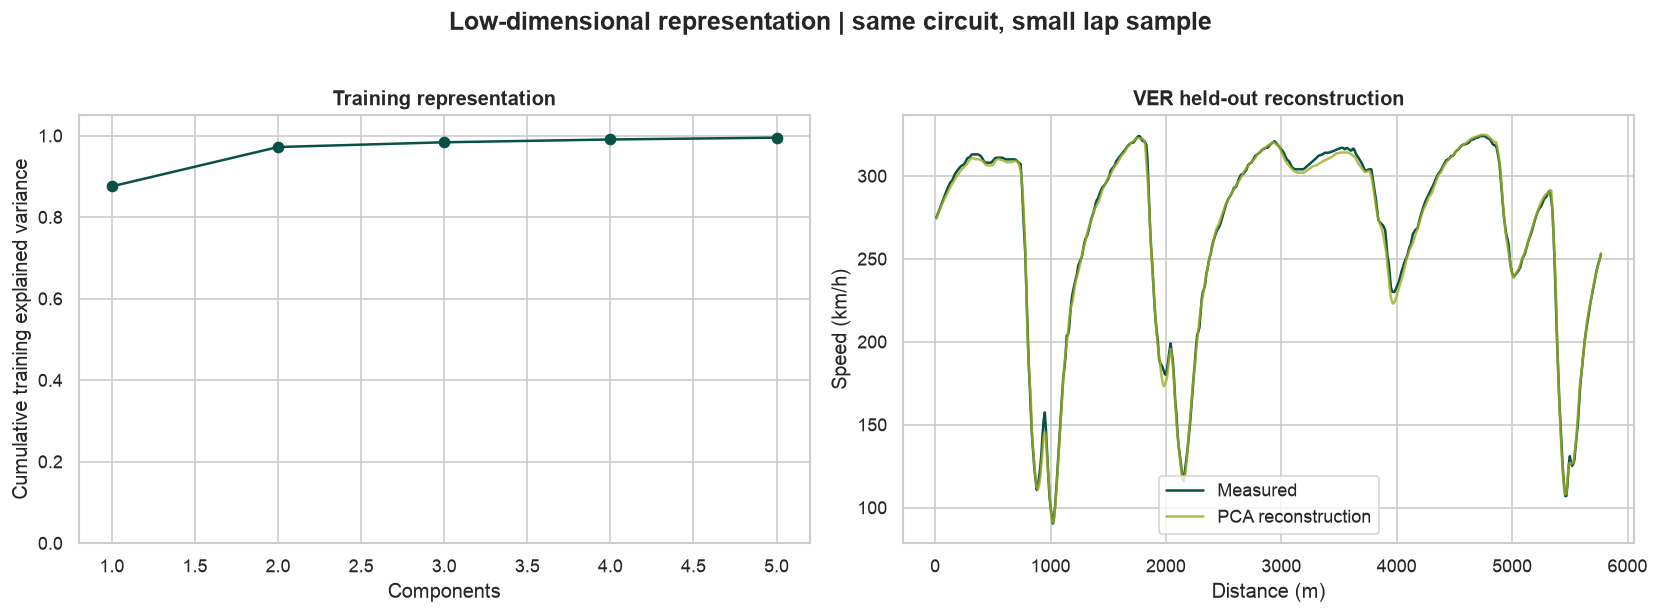

In [14]:
profile_meta=telemetry.groupby('lap_key').agg(driver=('driver','first'),split=('split','first'),max_distance=('distance_m','max'))
pca_grid=np.arange(10,np.floor(profile_meta.max_distance.min()/10)*10+1,10)
keys=profile_meta.index.to_list()
X=np.stack([np.interp(pca_grid,g.distance_m,g.speed_kmh) for key in keys for g in [telemetry[telemetry.lap_key.eq(key)].sort_values('distance_m')]])
split_array=profile_meta.split.to_numpy();train_ix=split_array=='train';val_ix=split_array=='validation';test_ix=split_array=='test'
pca_models={};pca_validation=[]
for k in [2,3,5]:
    if k>min(sum(train_ix),X.shape[1]):continue
    model=PCA(n_components=k,svd_solver='full').fit(X[train_ix]);pca_models[k]=model
    reconstructed=model.inverse_transform(model.transform(X[val_ix]))
    pca_validation.append({'components':k,**scores(X[val_ix].ravel(),reconstructed.ravel())})
chosen_k=min(pca_validation,key=lambda r:r['rmse'])['components'];pca=pca_models[chosen_k]
reconstructed=pca.inverse_transform(pca.transform(X[test_ix]))
pca_parts=[]
for j,key in enumerate(np.array(keys)[test_ix]):
    pca_parts.append(pd.DataFrame({'lap_key':key,'driver':profile_meta.loc[key,'driver'],'distance_m':pca_grid,
        'speed_kmh':X[test_ix][j],'pca_speed_kmh':reconstructed[j],'components':chosen_k,'split':'test','session_id':qsid}))
pca_profiles=pd.concat(pca_parts,ignore_index=True)
metric_rows.append(dict(task='pca_reconstruction',model=f'PCA {chosen_k} components',split='test',unit='km/h',ground_truth='Measured speed profile',
                        **scores(X[test_ix].ravel(),reconstructed.ravel())))
display(pd.DataFrame(pca_validation).round(3))
print('Training explained variance:',round(pca.explained_variance_ratio_.sum(),4))
fig,ax=plt.subplots(1,2,figsize=(14,5))
ax[0].plot(np.arange(1,chosen_k+1),np.cumsum(pca.explained_variance_ratio_),'o-',color='#075147')
ax[0].set(xlabel='Components',ylabel='Cumulative training explained variance',ylim=(0,1.05),title='Training representation')
a=pca_parts[0];ax[1].plot(a.distance_m,a.speed_kmh,label='Measured');ax[1].plot(a.distance_m,a.pca_speed_kmh,label='PCA reconstruction',alpha=.8)
ax[1].legend();ax[1].set(xlabel='Distance (m)',ylabel='Speed (km/h)',title=f'{a.driver.iloc[0]} held-out reconstruction')
finish('Low-dimensional representation | same circuit, small lap sample')

## 9. Surrogate of the simulator: a separate synthetic task

Here the labels come from my numerical simulator, **not track measurements**. I sample 2,400 constant-control scenarios: starting speed 20–90 m/s, duration 1–6 s, and balanced braking, lift and powered regimes. Effective coefficients stay fixed at the fitted values. A 0.05 s maximum Euler time step defines the reference simulator.

I train on starting speeds below 60 m/s, select polynomial ridge or random forest settings at 60–70 m/s, then test 70–90 m/s. This reserves a parameter region rather than random near-duplicate rows. The resulting extrapolation test is deliberately demanding. Errors measure fidelity to this specific discretised simulator. Even perfect fidelity would not validate real-car physics. Synthetic scenarios are explicitly labelled in the analysis tables.

,model,mae,rmse,max_abs_error,n
0,Polynomial ridge degree 2,1.9787,2.5343,6.3761,304
1,Polynomial ridge degree 3,0.9882,1.3562,5.9208,304
2,Surrogate random forest,3.9076,4.5617,17.1348,304


,mae,rmse,max_abs_error,n
regime,,,,
braking,4.3704,5.2870,15.5253,220.0
lift,1.7214,2.0087,5.7045,249.0
powered,2.3160,3.0197,8.7379,232.0


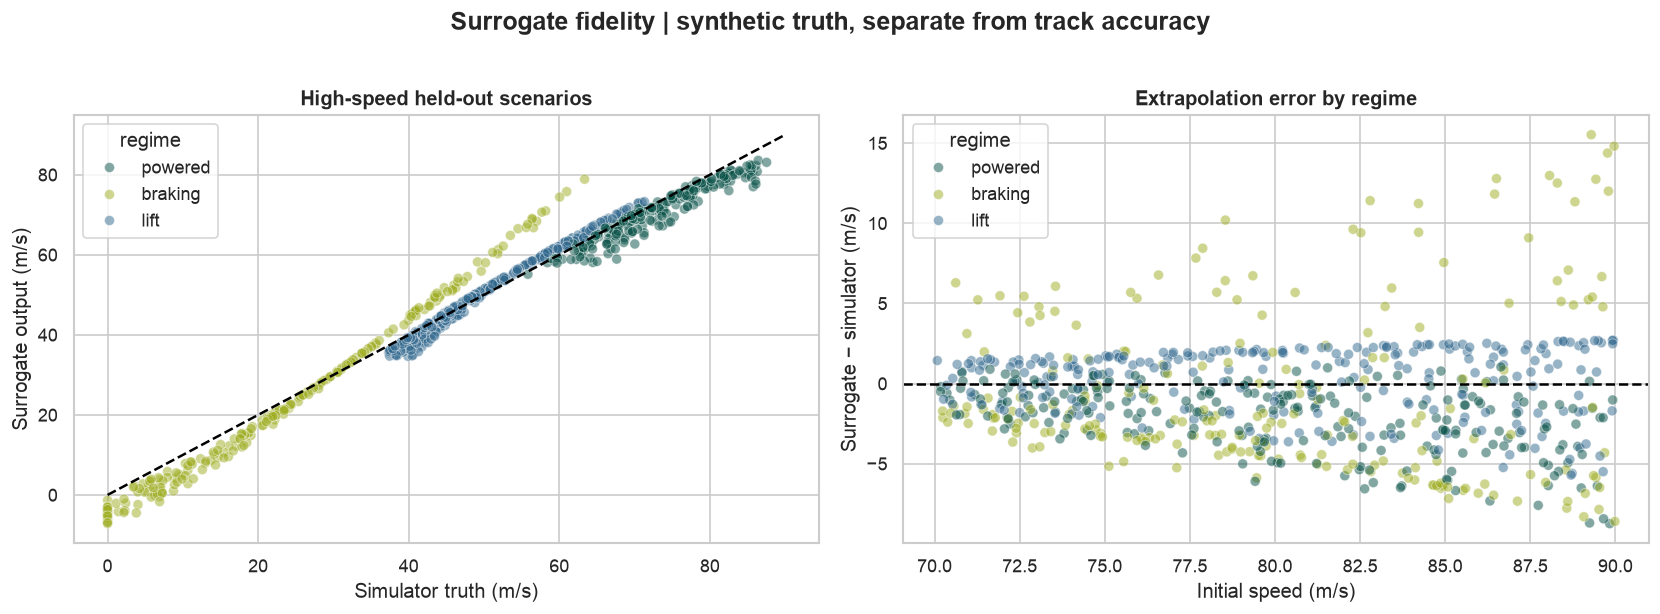

,batch_ms,amortised_ms_per_scenario
engine,,
Euler simulator,6.23083,0.04868
ML surrogate,0.42112,0.00329


Timing environment: macOS-26.6.2-arm64-arm-64bit arm64 ; repeated batch timings are retained in benchmark.


In [15]:
N=2400
scenarios=pd.DataFrame({'scenario_id':[f'S{i:04}' for i in range(N)],'v0_ms':rng.uniform(20,90,N),'duration_s':rng.uniform(1,6,N)})
scenarios['regime']=np.resize(['powered','lift','braking'],N)
scenarios['throttle_fraction']=np.where(scenarios.regime.eq('powered'),rng.uniform(.3,1,N),0.)
scenarios['brake_switch']=scenarios.regime.eq('braking').astype(int)
scenarios['split']=np.select([scenarios.v0_ms<60,scenarios.v0_ms<70],['train','validation'],default='test')
def scenario_simulator(frame):
    result=[]
    for row in frame.itertuples():
        t=np.linspace(0,row.duration_s,int(np.ceil(row.duration_s/.05))+1)
        result.append(simulate(theta,row.v0_ms,np.full(len(t),row.throttle_fraction),np.full(len(t),row.brake_switch),t)[0][-1])
    return np.array(result)
scenarios['simulator_final_speed_ms']=scenario_simulator(scenarios)
sf=['v0_ms','duration_s','throttle_fraction','brake_switch']
tr=scenarios.split.eq('train');va=scenarios.split.eq('validation');te=scenarios.split.eq('test')
surrogate_candidates={
    'Polynomial ridge degree 2':make_pipeline(PolynomialFeatures(2,include_bias=False),StandardScaler(),Ridge(alpha=1.)),
    'Polynomial ridge degree 3':make_pipeline(PolynomialFeatures(3,include_bias=False),StandardScaler(),Ridge(alpha=1.)),
    'Surrogate random forest':RandomForestRegressor(n_estimators=180,min_samples_leaf=3,random_state=SEED,n_jobs=-1)}
surrogate_validation=[]
for name,model in surrogate_candidates.items():
    model.fit(scenarios.loc[tr,sf],scenarios.loc[tr,'simulator_final_speed_ms'])
    surrogate_validation.append({'model':name,**scores(scenarios.loc[va,'simulator_final_speed_ms'],model.predict(scenarios.loc[va,sf]))})
surrogate_name=min(surrogate_validation,key=lambda x:x['mae'])['model'];surrogate=surrogate_candidates[surrogate_name]
scenarios['surrogate_final_speed_ms']=surrogate.predict(scenarios[sf])
scenarios['surrogate_error_ms']=scenarios.surrogate_final_speed_ms-scenarios.simulator_final_speed_ms
scenarios['synthetic']=True;scenarios['model']=surrogate_name
scenarios['out_of_training_range']=scenarios.v0_ms.ge(60)
for split in ['validation','test']:
    a=scenarios[scenarios.split.eq(split)]
    metric_rows.append(dict(task='simulator_surrogate',model=surrogate_name,split=split,unit='m/s',ground_truth='Synthetic simulator final speed',
                          **scores(a.simulator_final_speed_ms,a.surrogate_final_speed_ms)))
display(pd.DataFrame(surrogate_validation).round(4))
display(scenarios[te].groupby('regime').apply(lambda g:pd.Series(scores(g.simulator_final_speed_ms,g.surrogate_final_speed_ms)),include_groups=False).round(4))
fig,ax=plt.subplots(1,2,figsize=(14,5))
sns.scatterplot(data=scenarios[te],x='simulator_final_speed_ms',y='surrogate_final_speed_ms',hue='regime',ax=ax[0],alpha=.5)
ax[0].plot([0,90],[0,90],'k--');ax[0].set(title='High-speed held-out scenarios',xlabel='Simulator truth (m/s)',ylabel='Surrogate output (m/s)')
sns.scatterplot(data=scenarios[te],x='v0_ms',y='surrogate_error_ms',hue='regime',ax=ax[1],alpha=.5)
ax[1].axhline(0,color='black',ls='--');ax[1].set(xlabel='Initial speed (m/s)',ylabel='Surrogate − simulator (m/s)',title='Extrapolation error by regime')
finish('Surrogate fidelity | synthetic truth, separate from track accuracy')
# Identical 128-scenario batches, warmed up, sequential CPU timing, five repetitions.
batch=scenarios[te].iloc[:128].copy()
scenario_simulator(batch);surrogate.predict(batch[sf])
benchmark=[]
for repeat in range(5):
    for name,fn in [('Euler simulator',lambda:scenario_simulator(batch)),('ML surrogate',lambda:surrogate.predict(batch[sf]))]:
        start=time.perf_counter();fn();elapsed=time.perf_counter()-start
        benchmark.append({'engine':name,'repeat':repeat,'batch_size':len(batch),'batch_ms':elapsed*1000,
                          'amortised_ms_per_scenario':elapsed*1000/len(batch)})
benchmark=pd.DataFrame(benchmark)
display(benchmark.groupby('engine')[['batch_ms','amortised_ms_per_scenario']].median().round(5))
print('Timing environment:',platform.platform(),platform.machine(),'; repeated batch timings are retained in benchmark.')

The timing comparison measures these implementations on one machine, including dataframe handling and prediction overhead. It is not a universal speed claim or a single-call latency measurement. The simple simulator may be faster than the learned surrogate for small batches. The high-speed test is outside the surrogate training envelope; its predictions should be treated as a stress test, not a deployable emulator.

